### Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

### Membaca dataset

In [2]:
df = pd.read_csv('../dataset/jakarta_house.csv')

### Data Imputation / Mengisi Missing Value

In [3]:
# Land Area - Mean
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())

# Building Area - Mean
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())

### Validasi Hasil Imputasi

In [4]:
df.info()
print("\n=== Cek Missing Value Setelah Imputasi ===")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  str    
 3   city           10000 non-null  str    
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), str(2)
memory usage: 937.6 KB

=== Cek Missing Value Setelah Imputasi ===
index            0
price            0
district         0
city             0
bed_rooms        0
bath_rooms       0
carport          0
land_area        0
building_area    0
dtype: int64


### Deteksi Outlier

In [5]:
# Menentukan Kolom Numerik
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

# Menghitung Nilai Q1, Q3, IQR, Batas Outlier, dan Jumlah Outlier
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"\n===== {col} =====")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Batas Bawah :", batas_bawah)
    print("Batas Atas :", batas_atas)
    print("Jumlah Outlier :", jumlah_outlier)


===== price =====
Q1 : 2500000000.0
Q3 : 9800000000.0
IQR : 7300000000.0
Batas Bawah : -8450000000.0
Batas Atas : 20750000000.0
Jumlah Outlier : 1107

===== bed_rooms =====
Q1 : 3.0
Q3 : 5.0
IQR : 2.0
Batas Bawah : 0.0
Batas Atas : 8.0
Jumlah Outlier : 308

===== bath_rooms =====
Q1 : 2.0
Q3 : 4.0
IQR : 2.0
Batas Bawah : -1.0
Batas Atas : 7.0
Jumlah Outlier : 270

===== carport =====
Q1 : 1.0
Q3 : 2.0
IQR : 1.0
Batas Bawah : -0.5
Batas Atas : 3.5
Jumlah Outlier : 795

===== land_area =====
Q1 : 100.0
Q3 : 335.0
IQR : 235.0
Batas Bawah : -252.5
Batas Atas : 687.5
Jumlah Outlier : 881

===== building_area =====
Q1 : 139.0
Q3 : 400.0
IQR : 261.0
Batas Bawah : -252.5
Batas Atas : 791.5
Jumlah Outlier : 656


### Penanganan Outlier

In [6]:
# Menyimpan jumlah data awal
jumlah_awal = len(df)

while True:
    mask_outlier = pd.Series(False, index=df.index)

    for col in num_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        batas_bawah = Q1 - (1.5 * IQR)
        batas_atas = Q3 + (1.5 * IQR)

        mask_outlier |= (
            (df[col] < batas_bawah) |
            (df[col] > batas_atas)
        )

    jumlah_outlier = mask_outlier.sum()
    print("Outlier ditemukan :", jumlah_outlier)

    if jumlah_outlier == 0:
        break

    df = df[~mask_outlier]

# Mereset nomor indeks baris agar kembali berurutan 
df = df.reset_index(drop=True)

# Jumlah Data Setelah Penghapusan Outlier
print("\n=== Ringkasan Penghapusan Outlier ===")
print("Jumlah data sebelum :", jumlah_awal)
print("Jumlah data sesudah :", len(df))
print("Data yang terhapus :", jumlah_awal - len(df))

Outlier ditemukan : 1999
Outlier ditemukan : 1444
Outlier ditemukan : 773
Outlier ditemukan : 389
Outlier ditemukan : 284
Outlier ditemukan : 103
Outlier ditemukan : 63
Outlier ditemukan : 81
Outlier ditemukan : 0

=== Ringkasan Penghapusan Outlier ===
Jumlah data sebelum : 10000
Jumlah data sesudah : 4864
Data yang terhapus : 5136


### Validasi Hasil Penanganan Outlier

In [7]:
print("=== Sisa Outlier per Kolom ===")
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"{col} : {jumlah_outlier}")

=== Sisa Outlier per Kolom ===
price : 0
bed_rooms : 0
bath_rooms : 0
carport : 0
land_area : 0
building_area : 0


### Visualisasi Distribusi Data Setelah Penghapusan Outlier

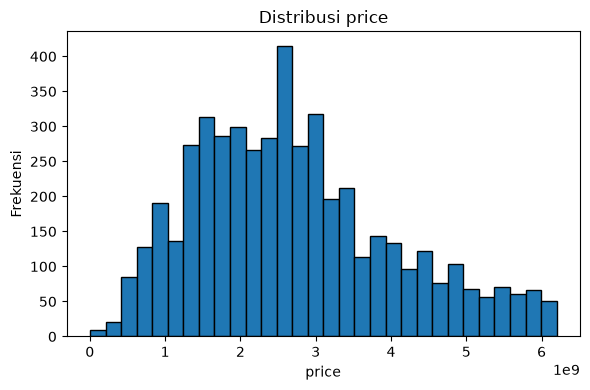

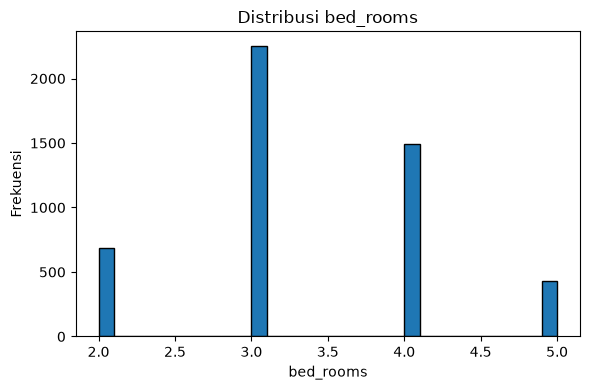

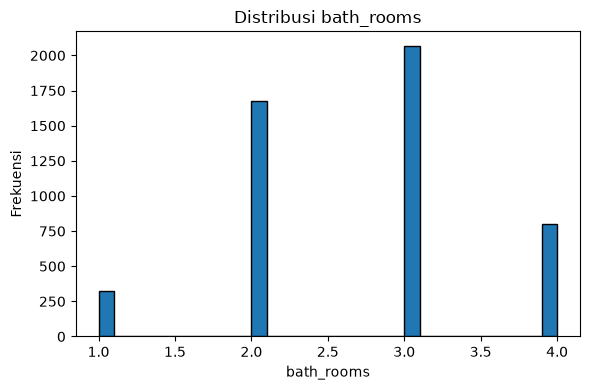

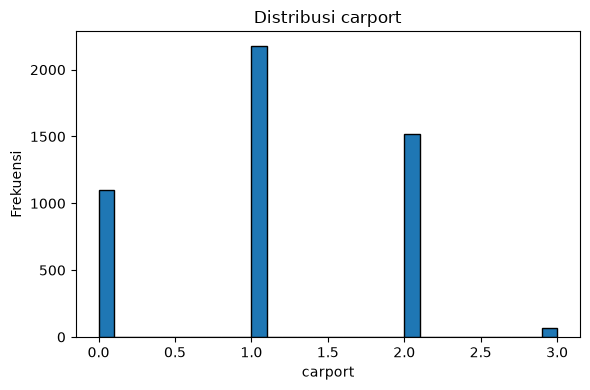

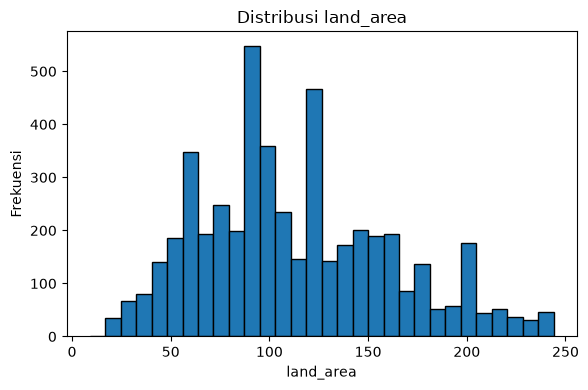

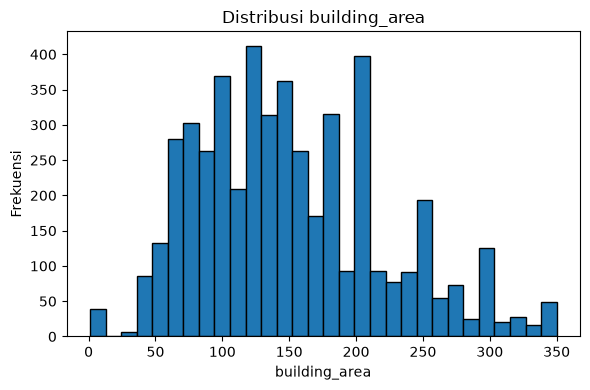

In [8]:
for col in num_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=30, edgecolor='black')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.tight_layout()
    plt.show()

### Visualisasi Boxplot Setelah Penghapusan Outlier

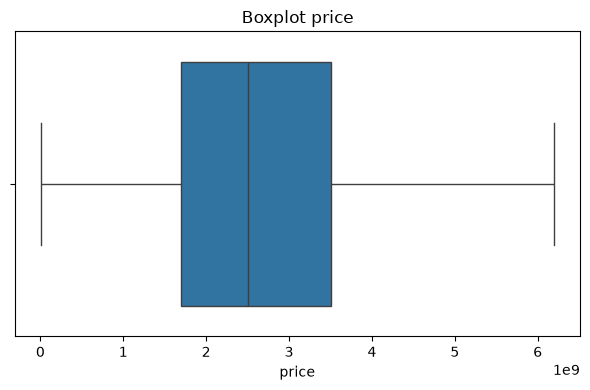

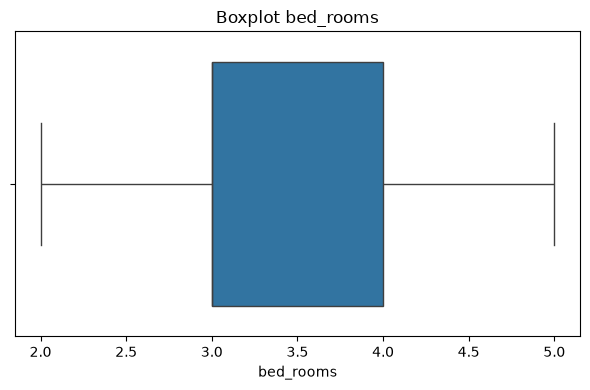

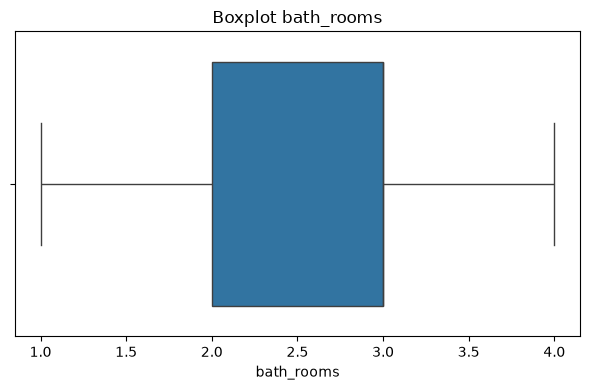

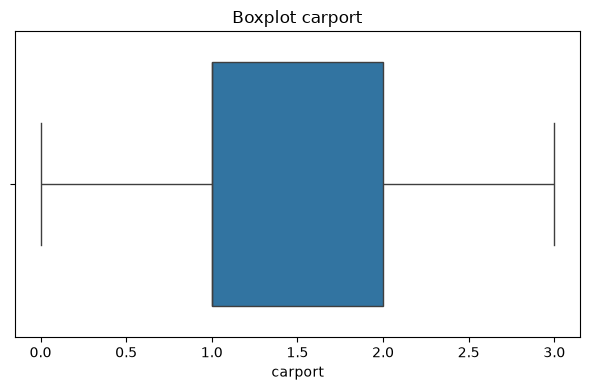

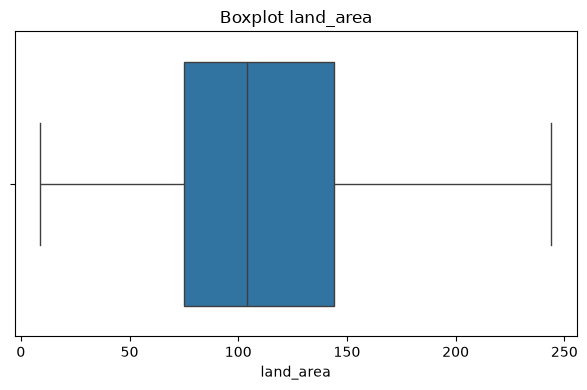

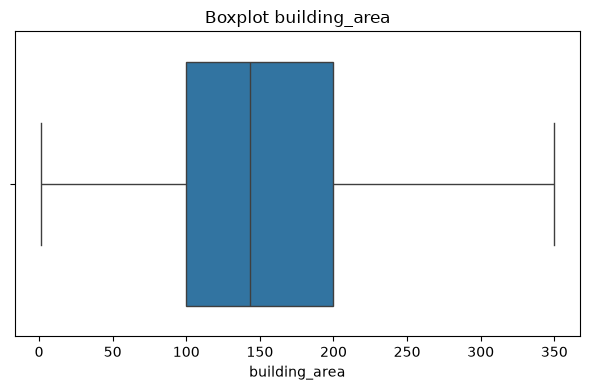

In [9]:
for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot {col}')
    plt.tight_layout()
    plt.show()

### Menyimpan Data Hasil Pra Pengolahan Data

In [10]:
joblib.dump(df, '../dataset/step_03_cleaned.pkl')
print("Data bersih berhasil disimpan ke '../dataset/step_03_cleaned.pkl'!")

Data bersih berhasil disimpan ke '../dataset/step_03_cleaned.pkl'!
